# Unit 4 · Natural Language & Conversational Visualization — Case-Based Activity
**Case:** *Auditing ChatViz at RideNow*

RideNow is a ride-hailing company. Its operations team has piloted **ChatViz**, a chat assistant that turns plain-language questions into charts and lets analysts keep refining them in conversation.
Before it goes to every analyst, you have been asked to **audit** it: how it reads a question, how it handles follow-ups, how it generates and validates chart specifications, how it edits charts, and what goes wrong.

**How to work**
* Run the cells from top to bottom. Do **not** edit the setup cell.
* Wherever you see `# TODO`, replace the placeholder (`None` or `""`) with your answer or code.
* Written answers: two or three sentences, using ideas from the lecture.

In [ ]:
import math, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20, "display.width", 140, "display.max_colwidth", 90)

In [ ]:
# ---------------- mini Vega-Lite-style renderer (do not edit) ----------------
import copy, json, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ACCENT, GREY, BLUE = "#E8710A", "#BDBDBD", "#4C72B0"

def apply_filters(df, spec):
    for t in spec.get("transform", []):
        f = t.get("filter")
        if not f:
            continue
        if "equal" in f:
            df = df[df[f["field"]] == f["equal"]]
        elif "oneOf" in f:
            df = df[df[f["field"]].isin(f["oneOf"])]
    return df

def is_horizontal(spec):
    e = spec["encoding"]
    return spec["mark"] == "bar" and e["x"].get("type") == "quantitative" and e["y"].get("type") in ("nominal", "ordinal")

def compute(spec, df):
    """Return the tidy table that the chart plots (used for drawing AND for checking values)."""
    enc, mark = spec["encoding"], spec["mark"]
    d = apply_filters(df, spec)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        return d[[x["field"], y["field"]] + ([sf] if sf else [])].copy()
    if x.get("bin"):
        return d[[x["field"]]].copy()
    cat, val = (y, x) if is_horizontal(spec) else (x, y)
    agg = val.get("aggregate", "mean")
    keys = [cat["field"]] + ([sf] if sf else [])
    out = d.groupby(keys).size().rename("value") if agg == "count" else d.groupby(keys)[val["field"]].agg(agg).rename("value")
    return out.reset_index()

def _order(labels, field, sort, totals):
    labels = list(dict.fromkeys(labels))
    if sort in ("-y", "-x"):
        return sorted(labels, key=lambda l: -totals[l])
    if sort in ("y", "x"):
        return sorted(labels, key=lambda l: totals[l])
    if field == "month":
        return sorted(labels, key=MONTHS.index)
    return sorted(labels)

def render_spec(spec, df, ax=None, figsize=(6, 3.4)):
    enc, mark = spec["encoding"], spec["mark"]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    t = compute(spec, df)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        if sf:
            for k, g in t.groupby(sf):
                ax.scatter(g[x["field"]], g[y["field"]], s=10, alpha=.6, label=str(k))
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
        else:
            ax.scatter(t[x["field"]], t[y["field"]], s=10, alpha=.5, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", y["field"]))
    elif x.get("bin"):
        ax.hist(t[x["field"]], bins=25, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", "count"))
    else:
        horiz = is_horizontal(spec)
        cat, val = (y, x) if horiz else (x, y)
        cf = cat["field"]
        tot = t.groupby(cf)["value"].sum()
        labels = _order(t[cf], cf, cat.get("sort"), tot)
        idx = np.arange(len(labels))
        series = sorted(t[sf].unique()) if sf else [None]
        for j, s in enumerate(series):
            g = t if s is None else t[t[sf] == s]
            vals = g.set_index(cf)["value"].reindex(labels).values
            if mark == "bar":
                w = 0.8 / len(series)
                pos = idx + (j - (len(series) - 1) / 2) * w
                colors = BLUE
                cond = c.get("condition")
                if s is None and cond:
                    colors = [ACCENT if l == cond["equal"] else c.get("value", GREY) for l in labels]
                (ax.barh if horiz else ax.bar)(pos, vals, w * 0.95, color=colors, label=None if s is None else str(s))
            else:
                ax.plot(idx, vals, marker="o", ms=3, label=None if s is None else str(s))
        (ax.set_yticks if horiz else ax.set_xticks)(idx)
        (ax.set_yticklabels if horiz else ax.set_xticklabels)(labels, fontsize=8)
        if horiz: ax.invert_yaxis()
        vtitle = val.get("title") or f"{val.get('aggregate', 'mean')}({val['field']})"
        ctitle = cat.get("title") or cat["field"]
        (ax.set_ylabel if not horiz else ax.set_xlabel)(vtitle)
        (ax.set_xlabel if not horiz else ax.set_ylabel)(ctitle)
        sc = val.get("scale", {})
        if sc.get("type") == "log":
            (ax.set_xscale if horiz else ax.set_yscale)("log")
        if mark == "bar" and sc.get("zero") is False:
            lo = t["value"].min() * 0.96
            (ax.set_xlim if horiz else ax.set_ylim)(lo, t["value"].max() * 1.02)
        if sf:
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
    ax.set_title(spec.get("title", ""), fontsize=10, fontweight="bold", loc="left")
    return ax

def show_specs(specs, df, ncols=3, w=4.6, h=3.3):
    n = len(specs); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, s in zip(axes.ravel(), specs):
        ax.axis("on"); render_spec(s, df, ax=ax)
    plt.tight_layout(); plt.show()

In [ ]:
# ---------------- synthetic RideNow trips (do not edit) ----------------
rng = np.random.default_rng(21)
n = 1200
city = rng.choice(["Bengaluru", "Hyderabad", "Chennai", "Pune"], n, p=[.38, .27, .20, .15])
vehicle = rng.choice(["Auto", "Mini", "Sedan", "Bike"], n, p=[.30, .35, .20, .15])
year = rng.choice([2024, 2025], n)
month = rng.choice(MONTHS, n)
distance = np.clip(rng.gamma(2.4, 2.6, n), 0.8, 30).round(1)
mult = {"Auto": 9, "Mini": 11, "Sedan": 14, "Bike": 6}
city_f = {"Bengaluru": 1.10, "Hyderabad": 1.00, "Chennai": 0.95, "Pune": 1.05}
fare = (35 + distance * np.array([mult[v] for v in vehicle]) * np.array([city_f[c] for c in city]) * rng.normal(1, .06, n)).round(0)
wait = np.clip(rng.gamma(2.2, 2.0, n) + (city == "Bengaluru") * 2.5, 0.5, None).round(1)
cancel_p = np.clip(0.03 + 0.004 * wait + (city == "Chennai") * 0.012 - (city == "Pune") * 0.01, 0.005, None)

df = pd.DataFrame({
    "city": city, "year": year, "month": month, "vehicle_type": vehicle, "distance_km": distance, "fare": fare, "wait_min": wait,
    "driver_rating": np.clip(rng.normal(4.4, .35, n) - 0.02 * wait, 1, 5).round(1),
    "payment_mode": rng.choice(["UPI", "Cash", "Card", "Wallet"], n, p=[.55, .20, .15, .10]),
    "cancelled": (rng.random(n) < cancel_p).astype(int),
})

# helpers used later (do not edit)
def spec_diff(a, b):
    def flat(d, p=""):
        out = {}
        for k, v in d.items():
            q = f"{p}.{k}" if p else k
            out.update(flat(v, q) if isinstance(v, dict) else {q: str(v)})
        return out
    fa, fb = flat(a), flat(b)
    return sorted(k for k in set(fa) | set(fb) if fa.get(k) != fb.get(k))

def lint_chart(spec):
    issues, t = [], spec.get("title", "").strip().lower()
    if not t: issues.append("no title")
    if re.match(r"^(this|the) (chart|figure|graph|plot) (shows|displays|presents)", t): issues.append("title describes the chart instead of asserting the point")
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if e.get("type") == "quantitative" and "title" not in e: issues.append(f"{ch}-axis has no title with units")
    return issues or ["OK"]

df.head()

,city,year,month,vehicle_type,distance_km,fare,wait_min,driver_rating,payment_mode,cancelled
0,Chennai,2025,Sep,Bike,4.8,59.0,2.3,5.0,UPI,0
1,Hyderabad,2024,Aug,Auto,9.9,122.0,4.7,4.5,Card,0
2,Chennai,2025,Aug,Mini,3.1,65.0,8.1,4.0,UPI,0
3,Bengaluru,2024,Sep,Mini,2.6,64.0,6.5,4.8,UPI,0
4,Hyderabad,2024,Sep,Mini,3.5,77.0,3.0,4.7,Cash,0


---
## Case 1 · How does ChatViz *read* a question? (NL2Vis, query → task abstraction, semantic parsing, ambiguity)
### 1a · From words to abstract tasks
Seven questions came in on the first day. For each one, name the **abstract task** ChatViz should infer.
Use exactly one of: `"trend"`, `"compare"`, `"extremes"`, `"distribution"`, `"correlation"`, `"part-to-whole"`, `"outliers"`.

In [ ]:
questions = {
    "Q1": "How did the number of rides change month by month in 2025?",
    "Q2": "Compare average fare across cities",
    "Q3": "Does fare depend on distance?",
    "Q4": "Which 2 cities had the highest cancellation rate?",
    "Q5": "How spread out are the driver ratings?",
    "Q6": "What percentage of rides are paid by UPI?",
    "Q7": "Compare auto and sedan fares over the last 2 years",
}
TASKS = ["trend", "compare", "extremes", "distribution", "correlation", "part-to-whole", "outliers"]
DEFAULT_CHART = {"trend": "line chart", "compare": "sorted bar chart", "extremes": "sorted bar, top-k highlighted", "distribution": "histogram / boxplot",
                 "correlation": "scatter plot", "part-to-whole": "stacked bar (few parts)", "outliers": "scatter / line with highlights"}
pd.Series(questions, name="question").to_frame()

,question
Q1,How did the number of rides change month by month in 2025?
Q2,Compare average fare across cities
Q3,Does fare depend on distance?
Q4,Which 2 cities had the highest cancellation rate?
Q5,How spread out are the driver ratings?
Q6,What percentage of rides are paid by UPI?
Q7,Compare auto and sedan fares over the last 2 years


In [ ]:
abstract_tasks = {
    "Q1": "trend",
    "Q2": "compare",
    "Q3": "correlation",
    "Q4": "extremes",
    "Q5": "distribution",
    "Q6": "part-to-whole",
    "Q7": "compare",   # the explicit "compare auto and sedan" cue dominates over the "last 2 years" time cue
}
assert all(v in TASKS for v in abstract_tasks.values()), "Choose each answer from TASKS"
pd.DataFrame({"question": questions, "your task": abstract_tasks}).assign(chart=lambda d: d["your task"].map(DEFAULT_CHART))

,question,your task,chart
Q1,How did the number of rides change month by month in 2025?,trend,line chart
Q2,Compare average fare across cities,compare,sorted bar chart
Q3,Does fare depend on distance?,correlation,scatter plot
Q4,Which 2 cities had the highest cancellation rate?,extremes,"sorted bar, top-k highlighted"
Q5,How spread out are the driver ratings?,distribution,histogram / boxplot
Q6,What percentage of rides are paid by UPI?,part-to-whole,stacked bar (few parts)
Q7,Compare auto and sedan fares over the last 2 years,compare,sorted bar chart


### 1b · Typos in attribute names
A user typed *"show avg **distnce** by city"*. ChatViz matches a word to a column using **similarity = 1 − d / max(len(a), len(b))**, where *d* is the Levenshtein distance,
and accepts the best match only if it is **≥ 0.7**; otherwise it must **ask, not guess**. The Levenshtein function is given; write `similarity` and `match_column`.

In [ ]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

known_columns = ["distance", "duration", "discount", "driver", "fare"]

In [ ]:
def similarity(a, b):
    d = levenshtein(a, b)
    return 1 - d / max(len(a), len(b))

def match_column(token, columns, threshold=0.7):
    best_col, best_sim = None, 0.0
    for col in columns:
        s = similarity(token, col)
        if s > best_sim:
            best_col, best_sim = col, s
    return best_col if best_sim >= threshold else None

for tok in ["distnce", "fre", "zzzz"]:
    print(f"{tok!r:10} -> {match_column(tok, known_columns)}")

assert match_column("distnce", known_columns) == "distance"
assert match_column("fre", known_columns) == "fare"
assert match_column("zzzz", known_columns) is None, "no column passes the threshold: ask the user"

'distnce'  -> distance
'fre'      -> fare
'zzzz'     -> None


### 1c · Handling ambiguity
ChatViz can resolve an ambiguous query in three ways: `"default + show interpretation"`, `"ambiguity widget"`, or `"clarifying question"`.
Pick the **best-fitting** strategy for each situation.

* **S1.** An analyst is exploring casually and types *"show fare"*. The table has `base_fare` and `total_fare`. A wrong guess costs nothing and she wants speed.
* **S2.** A manager types *"top rides"* and three things are unclear at once: **top by what** (fare / distance), **sum or average**, and **which year**. He can see the screen.
* **S3.** A chart for a regulator's filing is requested: *"average fare"*, and there is exactly **one** doubt: `fare` vs `fare_after_discount`. A wrong guess here is costly.

### Reflection: interpreting natural-language requests

Answer each question in two or three sentences, using ideas from the lecture and evidence from your work.

1. Which words or phrases in a user's question are most important for identifying the intended measure, dimensions, filters, and chart type? Explain why.

2. How should ChatViz respond when a user's request is ambiguous in more than one way? Give an example of a useful clarifying question.

3. How could different analysts interpret the same natural-language request differently? What design choices could make ChatViz's behavior more consistent?

_Your answer:_

1. Verbs like "compare," "trend," or "percentage" are the biggest signal for the task type, since they map almost
directly onto the abstract task list we used in 1a. Nouns that match (even loosely, like "distnce" matching
"distance") point to the measure and dimensions, and phrases like "in 2025" or "for Bengaluru" are the filter
cues. Getting the verb right matters most, since it decides the whole chart shape before anything else is chosen.

2. When more than one thing is unclear at once, like S2's "top rides" (top by what, sum or average, which year),
a single yes/no clarifying question isn't enough, that's exactly when the ambiguity widget makes sense, since it
lets the user pick all three uncertain pieces at a glance instead of going back and forth. A good clarifying
question for S2 would be: "Do you mean the rides with the highest total fare, or the highest average fare, and
for which year?"

3. Two analysts could read "top rides" completely differently, one might mean highest single fare, another
might mean the city with the most total rides. ChatViz can't read minds, so it should always show its
interpretation alongside the chart (the "default + show interpretation" strategy) so a wrong guess is at least
visible and correctable, rather than silently locking in one analyst's assumption as if it were the only
reading.

In [ ]:
ambiguity_strategy = {
    "S1": "default + show interpretation",
    "S2": "ambiguity widget",
    "S3": "clarifying question",
}
STRATEGIES = {"default + show interpretation", "ambiguity widget", "clarifying question"}
assert all(v in STRATEGIES for v in ambiguity_strategy.values()), "Use one of the three strategy names"

---
## Case 2 · Conversations (conversational systems, multi-turn refinement, follow-ups and context)
ChatViz keeps a **dialogue state**: the measure, aggregation, x field, colour field, filters and mark.
### 2a · Name the turn
For each utterance (said *after* a chart of mean fare by city), name the **turn type**, choosing from `TURN_TYPES`.
Then, for three follow-ups said after *"fares in Chennai in 2025"*, name the **context transition**: `"Continue"`, `"Retain"` or `"Shift"`.

In [ ]:
TURN_TYPES = ["Refine (filter)", "Elaborate (add field)", "Change aggregation", "Change view", "Drill down", "Compare", "Shift / reset"]
utterances = {
    "U1": "only for Bengaluru and Pune",
    "U2": "split it by vehicle type",
    "U3": "show the median instead",
    "U4": "as a line chart",
    "U5": "and how does that compare with 2024?",
    "U6": "now show driver ratings by city",
}
follow_ups = {
    "T1": "by vehicle type",
    "T2": "what about wait times?",
    "T3": "show cancellations by city",
}
display(pd.Series(utterances, name="utterance").to_frame()); display(pd.Series(follow_ups, name="follow-up").to_frame())

,utterance
U1,only for Bengaluru and Pune
U2,split it by vehicle type
U3,show the median instead
U4,as a line chart
U5,and how does that compare with 2024?
U6,now show driver ratings by city


,follow-up
T1,by vehicle type
T2,what about wait times?
T3,show cancellations by city


In [ ]:
turn_types = {
    "U1": "Refine (filter)",
    "U2": "Elaborate (add field)",
    "U3": "Change aggregation",
    "U4": "Change view",
    "U5": "Compare",
    "U6": "Shift / reset",
}
transitions = {
    "T1": "Continue",
    "T2": "Retain",
    "T3": "Shift",
}
assert all(v in TURN_TYPES for v in turn_types.values()), "Choose from TURN_TYPES"
assert all(v in {"Continue", "Retain", "Shift"} for v in transitions.values()), "Use Continue, Retain or Shift"

### 2b · Update the dialogue state
Complete `apply_turn(state, turn, **kw)`. It must return a **new** state (never modify the old one) and only change the slot that the turn affects:

| `turn` | keyword | change |
|---|---|---|
| `"refine"` | `field`, `values` | set `filters[field] = values` |
| `"elaborate"` | `field` | `color = field` |
| `"change_agg"` | `agg` | `agg = agg` |
| `"change_view"` | `mark` | `mark = mark` |
| `"shift"` | `new_state` | return `new_state` (everything old is dropped) |

In [ ]:
import copy

def apply_turn(state, turn, **kw):
    new = copy.deepcopy(state)
    if turn == "refine":
        new["filters"][kw["field"]] = kw["values"]
    elif turn == "elaborate":
        new["color"] = kw["field"]
    elif turn == "change_agg":
        new["agg"] = kw["agg"]
    elif turn == "change_view":
        new["mark"] = kw["mark"]
    elif turn == "shift":
        return kw["new_state"]
    return new

s0 = {"measure": "fare", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"}
s1 = apply_turn(s0, "refine", field="year", values=[2025])
s2 = apply_turn(s1, "refine", field="city", values=["Chennai", "Pune"])
s3 = apply_turn(s2, "elaborate", field="vehicle_type")
s4 = apply_turn(s3, "change_agg", agg="median")
s5 = apply_turn(s4, "change_view", mark="line")
s6 = apply_turn(s5, "shift", new_state={"measure": "driver_rating", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"})
for i, s in enumerate([s0, s1, s2, s3, s4, s5, s6]): print(i, s)

assert s0["filters"] == {}, "apply_turn must not modify the old state"
assert s2["filters"] == {"year": [2025], "city": ["Chennai", "Pune"]}, "earlier filters must be inherited"
assert s5["agg"] == "median" and s5["color"] == "vehicle_type" and s5["mark"] == "line" and s5["measure"] == "fare"
assert s6["filters"] == {} and s6["measure"] == "driver_rating", "a shift must reset everything"

0 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}
1 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025]}, 'mark': 'bar'}
2 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
3 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
4 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
5 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'line'}
6 {'measure': 'driver_rating', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}


### 2c · Why long conversations are fragile
ChatViz resolves each dependent follow-up correctly with probability **p = 0.92**, and every turn builds on the previous one, so the chance that a whole session is correct is **pⁿ**.
Compute: (1) the chance a **6-turn** session is fully correct; (2) the same after an upgrade to **p = 0.97**; (3) the smallest number of turns after which the chance falls **below 0.5** at p = 0.92.

### Reflection: conversational context and follow-ups

4. What information from the previous turn must ChatViz preserve when a user says, "Now show that by region?" What could go wrong if it does not preserve that context?

5. When should a follow-up request be interpreted as a modification of the current chart rather than as a new visualization request?

6. How would you test whether ChatViz handles pronouns and references such as "that," "those," or "the same trend" correctly across several turns?

_Your answer:_

4. "That" refers to whatever measure and filters were already active - ChatViz needs to hang onto the current
measure, aggregation and any filters, and just add region as a new grouping field. If it drops the existing
filters (like T3 in 2a effectively did), the analyst gets a chart for the wrong scope without any warning, which
is exactly the kind of silent context drift the lecture warns about.

5. It's a modification when the new utterance only adds, removes or swaps one piece of an otherwise-intact
request - a field, a filter, an aggregation, a mark, the way U1 through U4 did in 2a. Once the utterance names
a completely different measure with no obvious tie to the current chart (like U6, "now show driver ratings by
city"), that's a reset, not a modification, and the old state shouldn't be dragged along with it.

6. I'd run a fixed multi-turn script - start a chart, then issue a chain of pronoun-based follow-ups ("make
that a line chart," "highlight the same trend for Pune") -- and check after every turn whether the resolved
dialogue state still points at the field the previous chart was actually showing, not some default or the
most-recently-typed noun. Given our p = 0.92 per-turn accuracy, a 6-turn chain like this only has a 60.6% chance
of staying fully correct end to end, so testing single turns in isolation wouldn't catch failures that only show
up after several references in a row.

In [ ]:
p = 0.92
session_6_turns = p ** 6
session_6_better = 0.97 ** 6

turns_below_half = 1
while p ** turns_below_half >= 0.5:
    turns_below_half += 1

print(session_6_turns, session_6_better, turns_below_half)

0.6063550013440001 0.8329720049289998 9


---
## Case 3 · ChatViz's text-to-chart engine (prompting strategies, generate → execute → repair)
### 3a · Fix the prompt
Five problems were reported. Match each to the **prompting strategy** that targets it, using exactly one of:
`"Zero-shot"`, `"Few-shot"`, `"Schema + samples"`, `"Plan, then code"`, `"Design rules"`, `"Self-repair loop"`.

* **P1.** The model keeps plotting columns such as `avg_fare` that don't exist.
* **P2.** Different runs return code in different styles, and a downstream tool needs one fixed output format.
* **P3.** Analysts want to read the reasoning (fields, aggregation, chart) *before* any code runs.
* **P4.** Generated charts keep using 3-D pies and unlabelled axes.
* **P5.** The code sometimes crashes on a mistyped column name, and users should never see that.

In [ ]:
prompt_fix = {
    "P1": "Schema + samples",
    "P2": "Few-shot",
    "P3": "Plan, then code",
    "P4": "Design rules",
    "P5": "Self-repair loop",
}
STRATS = {"Zero-shot", "Few-shot", "Schema + samples", "Plan, then code", "Design rules", "Self-repair loop"}
assert all(v in STRATS for v in prompt_fix.values()), "Use one of the six strategy names"

### 3b · The Generate → Execute → Repair loop
Finish `generate_execute_repair`: generate code, execute it, and **on error send the error + schema back** to the LLM (`build_repair_prompt`). Allow at most `max_tries` attempts.
If every attempt fails, return `(None, max_tries)` so the interface can **ask the user** instead of showing garbage. On success return `(code, attempt_number)`.

### Reflection: generating, executing, and repairing charts

7. What should ChatViz do when the requested field does not exist, has an unexpected type, or contains too many missing values?

8. Which errors should ChatViz explain to the analyst, and which implementation details can remain hidden? Justify your boundary between helpful transparency and unnecessary technical detail.

9. How could an apparently valid chart still mislead an analyst? Discuss one issue involving aggregation, scale, missing data, or the choice of visual encoding.

_Your answer:_

7. If the field genuinely doesn't exist, like "customer happiness" in our test, the repair loop should try close
matches first (that's what `fake_llm`'s typo-fix branch does), and if nothing close enough is found after a few
tries, it should give up and ask the user instead of inventing a column which is exactly what our assert
checks (3 failed tries, then `None`). Unexpected types or heavy missingness should trigger a warning in the
chart itself rather than a silent crash or a silently wrong aggregation.

8. The analyst should see errors that affect what they're actually looking at a dropped filter, a column that
doesn't exist, a field substituted for a close match because those change whether the chart answers their
real question. Stack traces, retry counts and internal repair-loop mechanics can stay hidden, since knowing
*that* the system fixed a typo on attempt 2 doesn't help the analyst trust the chart any more than just seeing
the clean result would.

9. The Case 6 incidents are the clearest example: I1's chart ran without any error, had a sensible-looking
title ("Average fare by city"), and rendered fine but it was actually plotting totals, not averages, so
Bengaluru looked biggest purely because it has the most rides, not the highest fares. Nothing about the chart
*looked* broken; the validation would have to actually check the aggregation against the user's intent (like our
`check_sanity` function does) to catch it, since visually a bar chart of sums and a bar chart of means look
identical.

In [ ]:
import difflib

TEMPLATE = "fig, ax = plt.subplots(figsize=(5, 3))\nt = df.groupby('city')['{col}'].mean()\nax.bar(t.index, t.values)\nax.set_title('Mean {col} by city')"

def build_prompt(question, df):
    return f"Write matplotlib code using DataFrame df.\nColumns: {', '.join(df.columns)}\nQuestion: {question}"

def build_repair_prompt(question, df, error):
    return build_prompt(question, df) + f"\nERROR: {error}\nFix the code. Only use the columns listed above."

def fake_llm(prompt):                                   # a stand-in for the real LLM
    if "ERROR:" in prompt:
        m = re.search(r"Column not found: (\w+)", prompt)
        cols = re.search(r"Columns: (.*)", prompt).group(1).split(", ")
        fix = difflib.get_close_matches(m.group(1) if m else "", cols, n=1, cutoff=0.6)
        return TEMPLATE.format(col=fix[0]) if fix else "raise ValueError('no matching column')"
    q = prompt.split("Question:")[1].lower()
    if "happiness" in q: return TEMPLATE.format(col="happiness")      # invented column
    return TEMPLATE.format(col="far")                                  # typo for 'fare'

def execute(code_str, df):
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt}); return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"

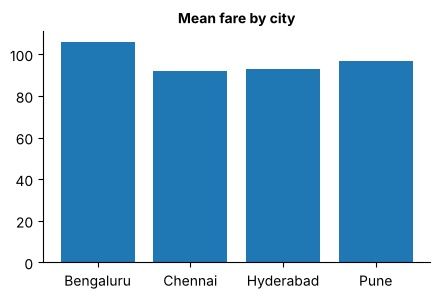

question 1 -> success after 2 attempt(s)
question 2 -> ASK THE USER after 3 attempt(s)


In [ ]:
def generate_execute_repair(question, df, llm, max_tries=3):
    prompt = build_prompt(question, df)
    for attempt in range(1, max_tries + 1):
        code_str = llm(prompt)
        err = execute(code_str, df)
        if err is None:
            plt.show()
            return code_str, attempt
        plt.close("all")
        prompt = build_repair_prompt(question, df, err)
    return None, max_tries

code_ok, tries_ok = generate_execute_repair("average fare by city", df, fake_llm)
code_bad, tries_bad = generate_execute_repair("average customer happiness by city", df, fake_llm)
print("question 1 ->", "success" if code_ok else "failed", "after", tries_ok, "attempt(s)")
print("question 2 ->", "success" if code_bad else "ASK THE USER", "after", tries_bad, "attempt(s)")

assert code_ok is not None and tries_ok == 2, "the typo should be repaired on the second attempt"
assert code_bad is None and tries_bad == 3, "an invented column cannot be repaired: ask the user after 3 tries"

---
## Case 4 · Specs, not just code (Vega-Lite specs, validation, evaluation)
ChatViz can also return a **chart specification** (a Vega-Lite-style dictionary). The question was **"average fare by vehicle type in 2025, as a bar chart"**.
Four candidate specs came back from the LLM; one is correct.

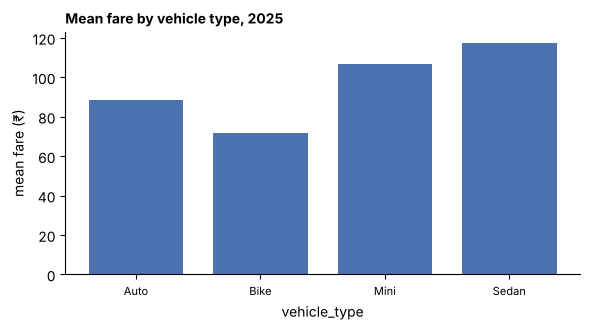

In [ ]:
intent = {"aggregate": "mean", "filters": {"year": [2025]}}

good = {"title": "Mean fare by vehicle type, 2025", "transform": [{"filter": {"field": "year", "equal": 2025}}], "mark": "bar",
        "encoding": {"x": {"field": "vehicle_type", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}

import copy as _copy
B1 = _copy.deepcopy(good); B1["encoding"]["colour"] = {"field": "city", "type": "nominal"}                                     # key typo
B2 = _copy.deepcopy(good); B2["encoding"]["y"]["field"] = "fare_amount"                                                         # invented field
B3 = _copy.deepcopy(good); B3["encoding"]["shape"] = {"field": "wait_min", "type": "quantitative"}                              # wrong channel
B4 = _copy.deepcopy(good); B4["transform"] = []; B4["encoding"]["y"]["aggregate"] = "sum"                                       # wrong aggregate + filter dropped
specs = {"good": good, "B1": B1, "B2": B2, "B3": B3, "B4": B4}
render_spec(good, df); plt.tight_layout(); plt.show()

### 4a · Write two of the four validation checks
The **schema** and **field** checks are written for you. Write the **type–channel** check (shape must not encode a quantitative field; size must not encode a nominal field)
and the **sanity** check (compare the spec with the user's `intent`: aggregation and filters). Each returns a list of problem strings (empty list = pass).

In [ ]:
import difflib
VALID_TOP = {"title", "data", "transform", "mark", "encoding"}
VALID_CH  = {"x", "y", "color", "shape", "size"}
VALID_KEYS = {"field", "type", "aggregate", "sort", "scale", "title", "condition", "value", "bin"}

def check_schema(spec):
    out = [f"unknown key '{k}'" for k in spec if k not in VALID_TOP]
    for ch, e in spec["encoding"].items():
        if ch not in VALID_CH:
            m = difflib.get_close_matches(ch, VALID_CH, 1)
            out.append(f"unknown channel '{ch}'" + (f" (did you mean '{m[0]}'?)" if m else ""))
    return out

def check_field(spec, df):
    used = [e["field"] for e in spec["encoding"].values() if isinstance(e, dict) and "field" in e]
    used += [t["filter"]["field"] for t in spec.get("transform", []) if "filter" in t]
    return [f"field '{f}' is not in the dataset" for f in used if f not in df.columns]

In [ ]:
def check_type_channel(spec):
    problems = []
    for ch, e in spec["encoding"].items():
        if not isinstance(e, dict):
            continue
        t = e.get("type")
        if ch == "shape" and t == "quantitative":
            problems.append("channel 'shape' must not encode a quantitative field")
        if ch == "size" and t == "nominal":
            problems.append("channel 'size' must not encode a nominal field")
    return problems

def check_sanity(spec, intent):
    problems = []
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if "aggregate" in e and e["aggregate"] != intent["aggregate"]:
            problems.append(f"{ch} aggregate '{e['aggregate']}' does not match intent '{intent['aggregate']}'")
    spec_filters = {t["filter"]["field"]: t["filter"].get("equal") for t in spec.get("transform", []) if "filter" in t}
    for field, values in intent["filters"].items():
        want = values[0] if len(values) == 1 else values
        if field not in spec_filters:
            problems.append(f"missing filter on '{field}'")
        elif spec_filters[field] != want:
            problems.append(f"filter on '{field}' does not match intent")
    return problems

def validate(spec, df, intent):
    return {"1 schema": check_schema(spec), "2 field": check_field(spec, df),
            "3 type-channel": check_type_channel(spec), "4 sanity": check_sanity(spec, intent)}

report = pd.DataFrame({name: {k: ("pass" if not v else "; ".join(v)) for k, v in validate(sp, df, intent).items()} for name, sp in specs.items()}).T
display(report)

assert check_type_channel(good) == [] and len(check_type_channel(B3)) == 1
assert check_sanity(good, intent) == [] and len(check_sanity(B4, intent)) >= 2
assert check_type_channel(B1) == [] and check_sanity(B2, intent) == [], "each bad spec should be stopped by ITS check"

,1 schema,2 field,3 type-channel,4 sanity
good,pass,pass,pass,pass
B1,unknown channel 'colour' (did you mean 'color'?),pass,pass,pass
B2,pass,field 'fare_amount' is not in the dataset,pass,pass
B3,pass,pass,channel 'shape' must not encode a quantitative field,pass
B4,pass,pass,pass,y aggregate 'sum' does not match intent 'mean'; missing filter on 'year'


### 4b · Evaluate ChatViz on a benchmark
ChatViz was tested on 6 benchmark queries. The table records which **components** of its output matched the reference spec and whether the **plotted values** were right.
Compute: `exact_match` per query (all five components correct), the **exact-match rate**, the **execution accuracy** (values right), the **component accuracies**, and the list of queries that count for execution accuracy but **not** for exact match.

### Reflection: specifications and evaluation

10. Why should ChatViz validate a generated chart specification before executing it? Identify two checks that would improve reliability.

11. What evidence would convince you that ChatViz is ready for wider deployment? Propose three evaluation criteria, including at least one about correctness and one about user experience.

_Your answer:_

10. Our own benchmark shows why -- 4 out of 6 queries had a chart render just fine (values_right True for Q3 and
Q6) even though the chart itself was wrong on some component, meaning "it ran without crashing" is nowhere near
"it's correct." The schema check and the sanity check both clearly help: schema catches typo'd keys like
`colour` before they silently do nothing, and sanity catches a mismatched aggregation or a dropped filter before
the chart ever gets drawn.

11. First, correctness: exact-match rate on a benchmark should clear some real threshold (ours is only 33%
right now, which isn't close to deployment-ready) rather than relying on execution accuracy alone, since that
number flatters the system by ignoring wrong-but-not-crashing charts. Second, repair behaviour: the self-repair
loop should resolve typo-level mistakes within 2 tries and correctly refuse to guess on invented fields, exactly
like our `generate_execute_repair` test. Third, user experience: analysts in a pilot should report that they
trust the chart's interpretation without needing to double-check the underlying numbers themselves, since I1
shows a confident, well-labeled chart can still be dead wrong.

In [ ]:
T, F = True, False
ev = pd.DataFrame({"chart":        [T, T, F, T, T, F],
                   "x":            [T, T, T, T, T, T],
                   "y":            [T, T, T, T, T, T],
                   "aggregation":  [T, F, T, T, T, T],
                   "filter":       [T, T, T, F, T, T],
                   "values_right": [T, F, T, F, T, T]}, index=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"])
COMPONENTS = ["chart", "x", "y", "aggregation", "filter"]
ev

,chart,x,y,aggregation,filter,values_right
Q1,True,True,True,True,True,True
Q2,True,True,True,False,True,False
Q3,False,True,True,True,True,True
Q4,True,True,True,True,False,False
Q5,True,True,True,True,True,True
Q6,False,True,True,True,True,True


In [ ]:
ev["exact_match"] = ev[COMPONENTS].all(axis=1)

exact_match_rate = ev["exact_match"].mean()
execution_accuracy = ev["values_right"].mean()
component_acc = {c: ev[c].mean() for c in COMPONENTS}
ea_not_em = list(ev[ev["values_right"] & ~ev["exact_match"]].index)

print(exact_match_rate, execution_accuracy, component_acc, ea_not_em)

0.3333333333333333 0.6666666666666666 {'chart': np.float64(0.6666666666666666), 'x': np.float64(1.0), 'y': np.float64(1.0), 'aggregation': np.float64(0.8333333333333334), 'filter': np.float64(0.8333333333333334)} ['Q3', 'Q6']


---
## Case 5 · Editing the chart by talking to it (conversational chart editing, salience, titles)
An analyst asks ChatViz for *mean fare by city* and then edits it with four utterances. Each edit must be a **minimal patch** to the spec.

In [ ]:
base = {"title": "Mean fare by city", "transform": [], "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}
g = df.groupby("city")["fare"].mean()
focus_city = g.idxmax()
print("focus city:", focus_city, "| mean fare ₹%.0f vs ₹%.0f for the other cities on average" % (g.max(), g.drop(focus_city).mean()))

focus city: Bengaluru | mean fare ₹106 vs ₹94 for the other cities on average


### 5a · Four edits
Write the patches (start from a **deep copy** so `base` is never modified):
1. *"sort highest first"* → set `sort` to `"-y"` on the **x** encoding
2. *"make the bars horizontal"* → swap the `x` and `y` encodings
3. *"highlight the focus city in orange"* → set `encoding["color"]` to `{"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}`
4. *"add a title that says the point"* → a title that **asserts** the point and **names the focus city** (not "This chart shows …")

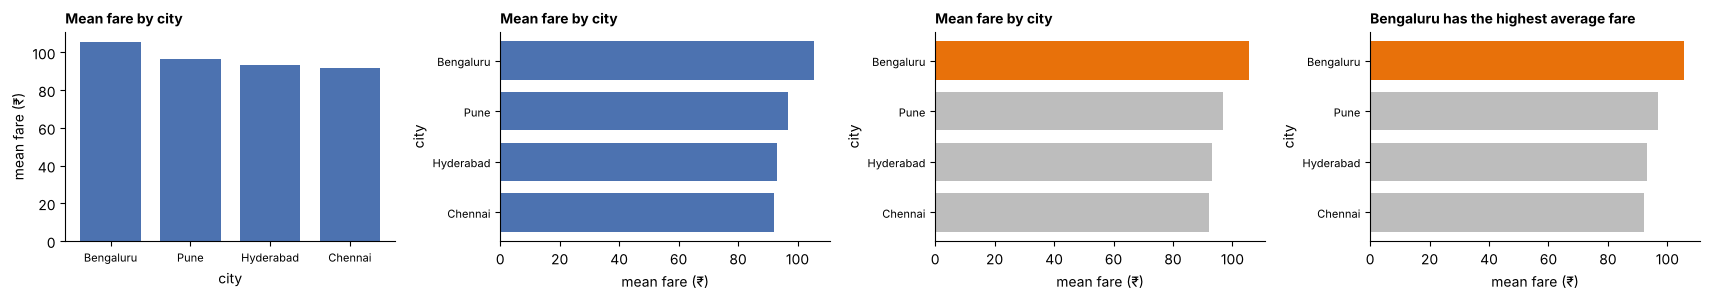

In [ ]:
import copy

spec1 = copy.deepcopy(base)
spec1["encoding"]["x"]["sort"] = "-y"

spec2 = copy.deepcopy(spec1)
spec2["encoding"]["x"], spec2["encoding"]["y"] = spec2["encoding"]["y"], spec2["encoding"]["x"]

spec3 = copy.deepcopy(spec2)
spec3["encoding"]["color"] = {"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}

spec4 = copy.deepcopy(spec3)
spec4["title"] = f"{focus_city} has the highest average fare"

show_specs([spec1, spec2, spec3, spec4], df, ncols=4, w=4.3, h=3.1)

assert spec_diff(base, spec1) == ["encoding.x.sort"], "edit 1 must change only the sort"
assert spec_diff(spec1, spec2) != [] and spec2["encoding"]["x"]["field"] == "fare", "edit 2: x and y must be swapped"
assert spec_diff(spec2, spec3) and all(p.startswith("encoding.color") for p in spec_diff(spec2, spec3)), "edit 3 must only add the colour encoding"
assert spec_diff(spec3, spec4) == ["title"], "edit 4 must change only the title"
assert focus_city in spec4["title"] and lint_chart(spec4) == ["OK"], f"title problems: {lint_chart(spec4)}"

### 5b · Make the answer pop out
A second question: *"Which city has the lowest cancellation rate?"* ChatViz answers with a rainbow-coloured bar chart and no annotation.
Write `bar_colors(labels, answer)` so that **only the answer bar** gets the accent colour and every other bar is grey, and write a one-line **annotation** that states the answer in words.

### Reflection: conversational chart editing

12. Compare making a chart change through natural language with changing it through a traditional visual interface. What are the main benefits and risks of the conversational approach?

13. If the user asks to "make it clearer," what additional information should ChatViz request before changing the chart? Suggest at least two possible interpretations.

_Your answer:_

12. Saying "sort highest first" is a lot faster than hunting through a menu for a sort toggle, and our 5a edits
show it can stay precise -- each utterance changed exactly one thing in the spec (`spec_diff` confirms it every
time). The risk is that natural language is vaguer than a UI control: a menu only has one "sort" button, but
"make it clearer" could mean a dozen different things, and if ChatViz guesses wrong the analyst might not even
notice the chart changed incorrectly, since there's no visible control that was "clicked."

13. "Make it clearer" could mean the labels and text are too small or unreadable, or it could mean there's too
much happening in the chart (too many bars, too much colour) and some of it should be dropped or aggregated
differently. ChatViz should ask which one before touching anything, since the fix for a readability problem
(bigger fonts, more whitespace) and the fix for an overcrowded chart (fewer categories, a different aggregation)
are completely different edits.

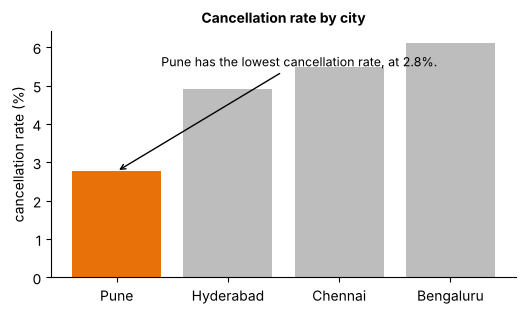

In [ ]:
rate = df.groupby("city")["cancelled"].mean().sort_values() * 100
answer = rate.index[0]

def bar_colors(labels, answer):
    return [ACCENT if l == answer else GREY for l in labels]

annotation = f"{answer} has the lowest cancellation rate, at {rate.loc[answer]:.1f}%."

colors = bar_colors(list(rate.index), answer)
assert colors.count(ACCENT) == 1 and colors.count(GREY) == len(rate) - 1
assert answer in annotation, "name the answer city in the annotation"

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(rate.index, rate.values, color=colors)
ax.annotate(annotation, xy=(0, rate.iloc[0]), xytext=(0.4, rate.max() * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylabel("cancellation rate (%)"); ax.set_title("Cancellation rate by city")
plt.show()

---
## Case 6 · Post-mortem: what went wrong in the pilot? (benefits, failure modes, the nested model, mitigations)
Six incidents were reported during the pilot.

| # | Incident |
|---|---|
| I1 | The manager asked for *average* fare per city. The chart's title says "Average", but the bars are **totals**, so Bengaluru (most rides) wins. |
| I2 | After *"only 2025"*, the follow-up *"what about cancellations?"* was drawn for **all years**, with no warning. |
| I3 | A chart was drawn of `driver_score`, a column that **does not exist**; the tool quietly filled it with random numbers. |
| I4 | A **line** was drawn connecting Auto, Mini, Sedan and Bike for *"compare average fare by vehicle type"*. |
| I5 | Bars comparing cancellation rates of 4.1 % and 4.4 % started the y-axis at 4 %, making one city look **twice as bad**. |
| I6 | The caption under a scatter plot read *"Surge pricing **causes** cancellations."* |

### 6a · Classify
**(i)** Label each incident with exactly one failure mode from `FAILURE_MODES`.
**(ii)** Place each statement in the right level of **Munzner's nested model** (`"domain"`, `"abstraction"`, `"idiom"`, `"algorithm"`).
**(iii)** Pick the best **mitigation** for each situation from `MITIGATIONS`.

* **L1.** The code crashes with a `KeyError`.
* **L2.** The tool answers a *trend* question when the analyst actually needed to *compare two groups*.
* **L3.** A 12-slice pie is used to compare ride counts.
* **L4.** Finance defines "revenue" net of driver incentives, but the tool uses gross fares.

Mitigation situations: **M1** — follow-ups silently drop filters (I2). **M2** — the tool keeps choosing pies and truncated axes (I4/I5). **M3** — a wrong aggregation slips through while the chart runs fine (I1). **M4** — a chart is about to go into the **board report**.

In [ ]:
FAILURE_MODES = ["hallucinated field", "wrong aggregation / filter", "wrong chart for the task", "misleading design", "context drift", "over-confident narrative"]
LEVELS = ["domain", "abstraction", "idiom", "algorithm"]
MITIGATIONS = ["echo the interpretation", "make choices editable", "validate before showing", "keep the spec / code", "constrain the design", "human review for decisions"]

In [ ]:
failure_mode = {
    "I1": "wrong aggregation / filter",
    "I2": "context drift",
    "I3": "hallucinated field",
    "I4": "wrong chart for the task",
    "I5": "misleading design",
    "I6": "over-confident narrative",
}
nested_level = {
    "L1": "algorithm",
    "L2": "abstraction",
    "L3": "idiom",
    "L4": "domain",
}
mitigation = {
    "M1": "echo the interpretation",
    "M2": "constrain the design",
    "M3": "validate before showing",
    "M4": "human review for decisions",
}

assert all(v in FAILURE_MODES for v in failure_mode.values()), "failure_mode: choose from FAILURE_MODES"
assert all(v in LEVELS for v in nested_level.values()), "nested_level: choose from LEVELS"
assert all(v in MITIGATIONS for v in mitigation.values()), "mitigation: choose from MITIGATIONS"

### 6b · Your recommendation
Incident **I1** looked perfectly fine on screen and was only noticed because a manager happened to check the numbers. In two or three sentences: **which level of the nested model do the costliest errors live at, why are they dangerous,
and what should SwiftBite-style rollout rules require before ChatViz goes to every analyst?** *(Use RideNow in your answer.)*

### Reflection: rollout priorities and safeguards

14. What safeguards are needed when a visualization could expose sensitive operational information, such as driver performance or neighborhood-level demand?

15. After auditing ChatViz, what is the single most important improvement you would prioritize, and why?


In [ ]:
final_recommendation = (
    "The costliest errors, like I1, live at the abstraction level -- the mapping from what the analyst asked for "
    "(average fare) to what the system actually computed (total fare) was wrong, but nothing about the rendered "
    "chart looked broken, so it passed every visual check a human would normally do at a glance. That's what "
    "makes abstraction-level errors so dangerous: schema and idiom-level problems (a missing field, an ugly pie "
    "chart) are obvious on sight, but a mislabeled aggregation looks completely legitimate until someone checks "
    "the actual numbers, which is exactly how RideNow's manager caught I1 by accident rather than by any "
    "safeguard. Before ChatViz goes to every analyst, RideNow should require that every generated spec passes a "
    "sanity check against the user's stated intent (like our check_sanity function) before it's shown, and that "
    "any chart headed for a report or external audience gets a human review, not just a pretty rendering."
)

---
### Before you finish
Run the cell below to see whether any answer has been left blank.

In [ ]:
_required = ["abstract_tasks", "ambiguity_strategy", "turn_types", "transitions", "session_6_turns", "session_6_better", "turns_below_half",
             "prompt_fix", "exact_match_rate", "execution_accuracy", "component_acc", "ea_not_em", "annotation",
             "failure_mode", "nested_level", "mitigation", "final_recommendation"]
_blank = []
for _name in _required:
    _v = globals().get(_name)
    if _v is None or (isinstance(_v, str) and not _v.strip()) or (isinstance(_v, dict) and any(x is None for x in _v.values())):
        _blank.append(_name)
print("All answers filled in." if not _blank else "Still blank: " + ", ".join(_blank))

All answers filled in.
